## 1. Считывание данных

In [21]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("data.txt", sep=";", skiprows=25, names=["start_date_time", "RCORR_E"])
df["start_date_time"] = pd.to_datetime(df["start_date_time"])
print("Всего наблюдений:", len(df))
df.head()

Всего наблюдений: 12960


,start_date_time,RCORR_E
0,2018-11-01 00:00:00,254.24
1,2018-11-01 00:01:00,262.77
2,2018-11-01 00:02:00,256.37
3,2018-11-01 00:03:00,251.33
4,2018-11-01 00:04:00,256.54


## 2. Нахождение пропусков и выбросов (3σ)

In [ ]:
gaps_mask = df["RCORR_E"].isna() | (df["RCORR_E"] == 0)

valid = df.loc[~gaps_mask, "RCORR_E"]
mean_val = valid.mean()
std_val = valid.std()
lower_bound = mean_val - 3 * std_val
upper_bound = mean_val + 3 * std_val

outliers_mask = ((df["RCORR_E"] < lower_bound) | (df["RCORR_E"] > upper_bound)) & ~gaps_mask

print(f"Среднее: {mean_val:.3f}, σ: {std_val:.3f}")
print(f"Границы 3σ: [{lower_bound:.2f}, {upper_bound:.2f}]")
df[gaps_mask | outliers_mask].assign(тип=lambda d: ["пропуск" if g else "выброс" for g in gaps_mask[d.index]])

Среднее: 258.979, σ: 57.105
Границы 3σ: [87.66, 430.29]


,start_date_time,RCORR_E,тип
254,2018-11-01 04:14:00,4752.63,выброс
258,2018-11-01 04:18:00,0.00,пропуск
5957,2018-11-05 03:17:00,2086.39,выброс
11679,2018-11-09 02:39:00,4563.22,выброс


In [16]:
n_total = len(df)
n_gaps = gaps_mask.sum()
n_out = outliers_mask.sum()

print(f"Пропусков: {n_gaps} ({n_gaps / n_total * 100:.4f} %)")
print(f"Выбросов:  {n_out} ({n_out / n_total * 100:.4f} %)")
print(f"Итого:     {n_gaps + n_out} ({(n_gaps + n_out) / n_total * 100:.4f} %) из {n_total}")

Пропусков: 1 (0.0077 %)
Выбросов:  3 (0.0231 %)
Итого:     4 (0.0309 %) из 12960


## 3. Медиана по данным без пропусков и выбросов

In [17]:
cleaned = df.loc[~gaps_mask & ~outliers_mask, "RCORR_E"]
median_value = cleaned.median()
print(f"Медиана по чистым данным: {median_value:.2f}")
print(f"Стандартное отклонение по чистым данным: {cleaned.std():.3f}")

Медиана по чистым данным: 258.14
Стандартное отклонение по чистым данным: 3.815


## 4. Замена пропусков и выбросов медианой

In [18]:
fixed_df = df.copy()
fixed_df.loc[gaps_mask | outliers_mask, "RCORR_E"] = median_value

print("NaN:", fixed_df["RCORR_E"].isna().sum(), "| нулей:", (fixed_df["RCORR_E"] == 0).sum())
pd.DataFrame({
    "время": df.loc[gaps_mask | outliers_mask, "start_date_time"],
    "было": df.loc[gaps_mask | outliers_mask, "RCORR_E"],
    "стало": fixed_df.loc[gaps_mask | outliers_mask, "RCORR_E"],
})

NaN: 0 | нулей: 0


,время,было,стало
254,2018-11-01 04:14:00,4752.63,258.14
258,2018-11-01 04:18:00,0.00,258.14
5957,2018-11-05 03:17:00,2086.39,258.14
11679,2018-11-09 02:39:00,4563.22,258.14


## 5. Графики исходного и полученного рядов

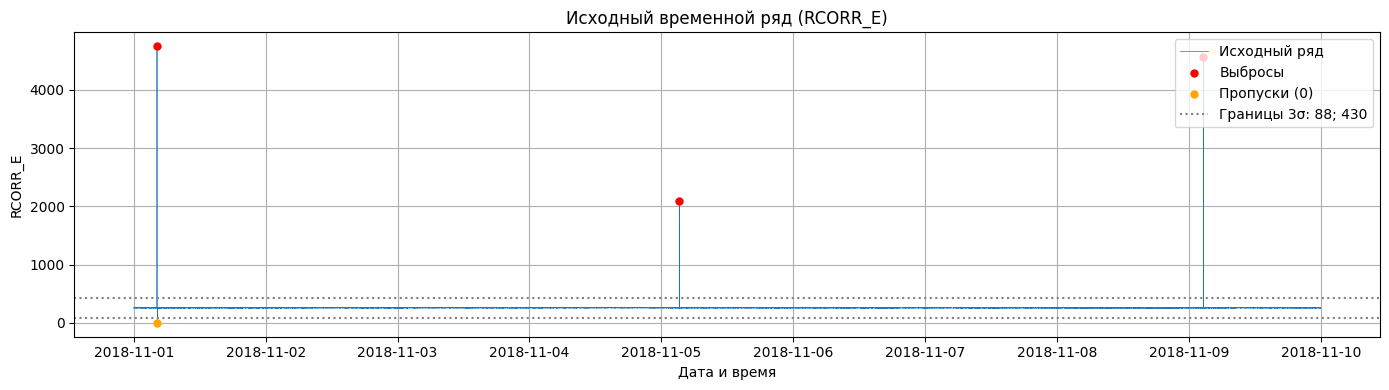

In [ ]:
plt.figure(figsize=(14, 4))
plt.plot(df["start_date_time"], df["RCORR_E"], linewidth=0.5, label="Исходный ряд")
plt.scatter(df.loc[outliers_mask, "start_date_time"], df.loc[outliers_mask, "RCORR_E"], color="red", s=25, zorder=3, label="Выбросы")
plt.scatter(df.loc[gaps_mask, "start_date_time"], df.loc[gaps_mask, "RCORR_E"], color="orange", s=25, zorder=3, label="Пропуски (0)")
plt.axhline(lower_bound, color="gray", linestyle=":", label=f"Границы 3σ: {lower_bound:.0f}; {upper_bound:.0f}")
plt.axhline(upper_bound, color="gray", linestyle=":")
plt.title("Исходный временной ряд (RCORR_E)")
plt.xlabel("Дата и время")
plt.ylabel("RCORR_E")
plt.grid(True)
plt.legend(loc="upper right")
plt.tight_layout()
plt.show()

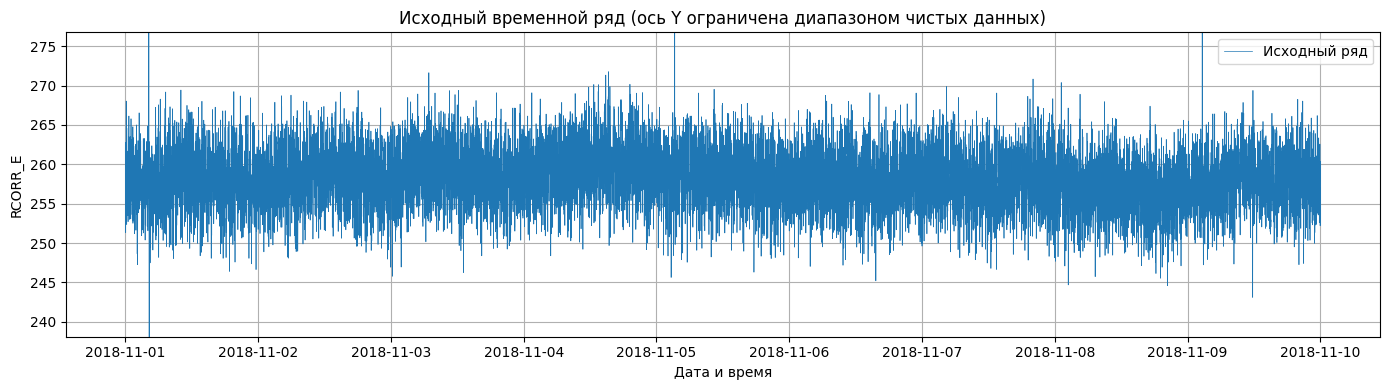

In [23]:
plt.figure(figsize=(14, 4))
plt.plot(df["start_date_time"], df["RCORR_E"], linewidth=0.5, label="Исходный ряд")
plt.ylim(cleaned.min() - 5, cleaned.max() + 5)
plt.title("Исходный временной ряд (ось Y ограничена диапазоном чистых данных)")
plt.xlabel("Дата и время")
plt.ylabel("RCORR_E")
plt.grid(True)
plt.legend(loc="upper right")
plt.tight_layout()
plt.show()

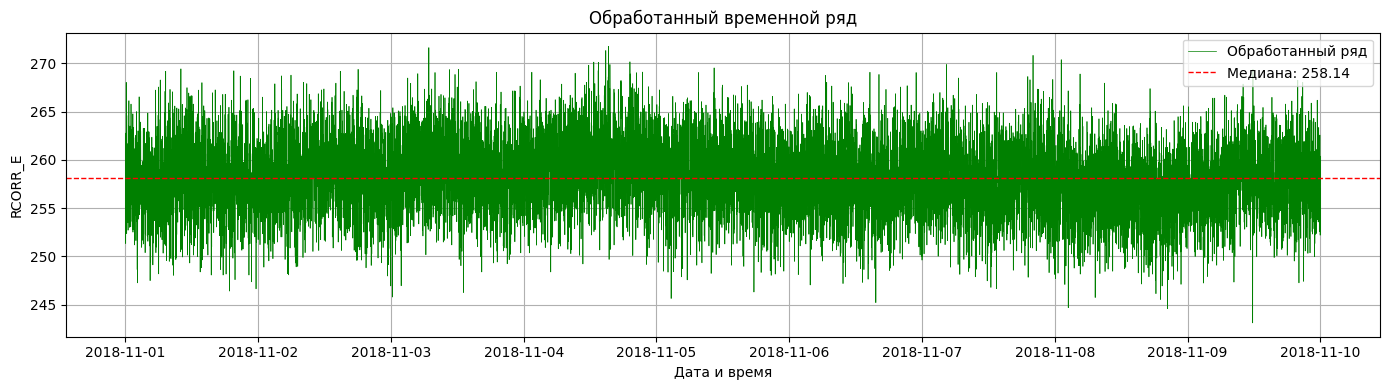

In [ ]:
plt.figure(figsize=(14, 4))
plt.plot(fixed_df["start_date_time"], fixed_df["RCORR_E"], linewidth=0.5, color="green", label="Обработанный ряд")
plt.axhline(median_value, color="red", linestyle="--", linewidth=1, label=f"Медиана: {median_value:.2f}")
plt.title("Обработанный временной ряд")
plt.xlabel("Дата и время")
plt.ylabel("RCORR_E")
plt.grid(True)
plt.legend(loc="upper right")
plt.tight_layout()
plt.show()